# Notebook 05 — Behavior & Feature Usage

> **SYNTHETIC DATA NOTICE:** All data is computer-generated. Findings describe only this simulated dataset.

**Business questions answered:**
- **Q5:** Does product/feature usage affect churn?
- **Q6:** Does inactivity predict churn?

**Evidence source:** `sql/07_feature_usage.sql`

**Leakage prevention:** All features computed from usage BEFORE the churn date.
Active customers use full history up to 2025-12-31.
Churned customers use only data in the 30/90 days PRIOR to their `end_date`.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np
from scipy import stats
from pathlib import Path

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120
FIGURES_DIR = Path('../outputs/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

conn = sqlite3.connect('../db/churn.db')
print('Connected.')

Connected.


## 1. Inactivity and Churn (Q6)

In [2]:
df_inact = pd.read_sql('SELECT * FROM churn_by_inactivity', conn)
print(df_inact.to_string(index=False))
print()
print('Relative risk of inactive vs active (approx):')
if len(df_inact) >= 2:
    hi = df_inact[df_inact['inactivity_group'].str.contains('Inactive')]['churn_pct'].values
    lo = df_inact[df_inact['inactivity_group'].str.contains('Active')]['churn_pct'].values
    if len(hi) > 0 and len(lo) > 0 and lo[0] > 0:
        print(f'  RR = {hi[0]/lo[0]:.2f}x — inactive customers churn at {hi[0]/lo[0]:.1f}x the rate of active customers.')
    else:
        print('  Could not compute relative risk (check data).')

            inactivity_group  total_customers  churned  churn_pct
Inactive (0 sessions in 30d)               13       12      92.31
 Active (1+ sessions in 30d)             2236      300      13.42

Relative risk of inactive vs active (approx):
  RR = 6.88x — inactive customers churn at 6.9x the rate of active customers.


<cell>:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


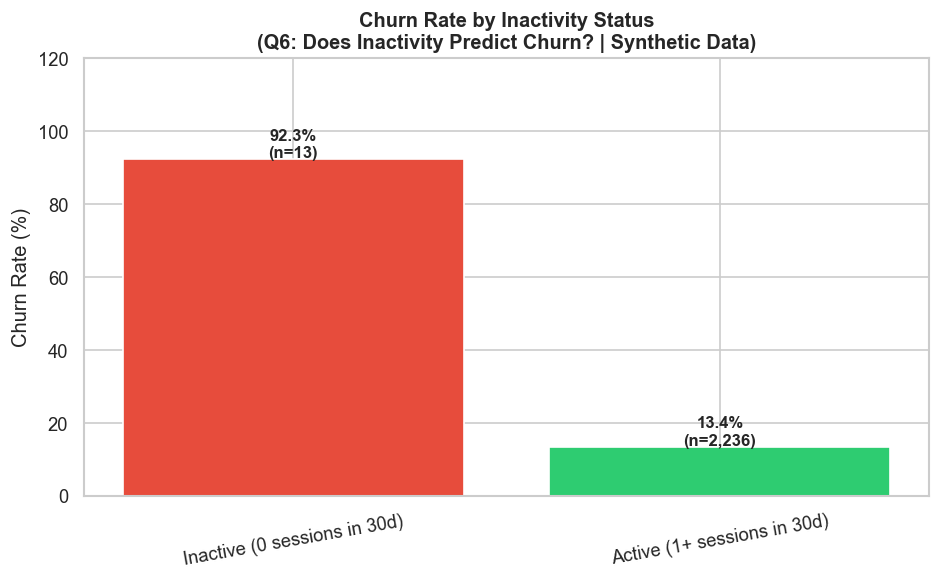

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#e74c3c' if 'Inactive' in g else '#2ecc71' for g in df_inact['inactivity_group']]
bars = ax.bar(df_inact['inactivity_group'], df_inact['churn_pct'], color=colors, edgecolor='white')
for bar, val, n in zip(bars, df_inact['churn_pct'], df_inact['total_customers']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{val:.1f}%\n(n={n:,})', ha='center', fontsize=10, fontweight='bold')
ax.set_title('Churn Rate by Inactivity Status\n(Q6: Does Inactivity Predict Churn? | Synthetic Data)', fontsize=12, fontweight='bold')
ax.set_ylabel('Churn Rate (%)')
ax.set_ylim(0, df_inact['churn_pct'].max() * 1.3)
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '05_inactivity_churn.png', bbox_inches='tight')
plt.show()

## 2. Feature Usage and Churn (Q5)

In [4]:
df_feat = pd.read_sql('SELECT * FROM churn_by_feature_use', conn)
print(df_feat.to_string(index=False))
print()
vals = df_feat['churn_pct'].values
if len(vals) == 2 and vals[1] > 0:
    print(f'Stickiness protection effect: users of collaboration feature churn at {vals[vals.argmin()]:.1f}% vs {vals[vals.argmax()]:.1f}% for non-users.')

       feature_group  total_customers  churned  churn_pct
No Collaboration Use              389      109      28.02
  Uses Collaboration             1860      203      10.91

Stickiness protection effect: users of collaboration feature churn at 10.9% vs 28.0% for non-users.


<cell>:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


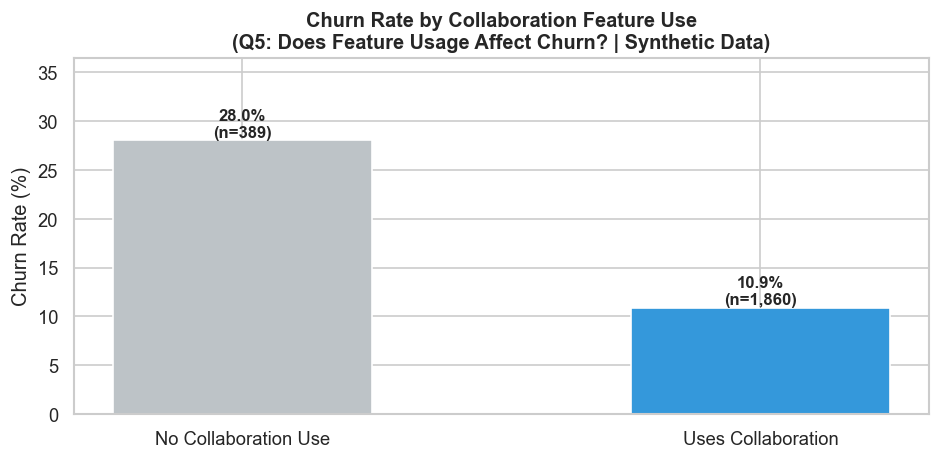

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = ['#3498db' if 'Uses' in g else '#bdc3c7' for g in df_feat['feature_group']]
bars = ax.bar(df_feat['feature_group'], df_feat['churn_pct'], color=colors, edgecolor='white', width=0.5)
for bar, val, n in zip(bars, df_feat['churn_pct'], df_feat['total_customers']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{val:.1f}%\n(n={n:,})', ha='center', fontsize=10, fontweight='bold')
ax.set_title('Churn Rate by Collaboration Feature Use\n(Q5: Does Feature Usage Affect Churn? | Synthetic Data)', fontsize=12, fontweight='bold')
ax.set_ylabel('Churn Rate (%)')
ax.set_ylim(0, df_feat['churn_pct'].max() * 1.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '05_feature_use_churn.png', bbox_inches='tight')
plt.show()

## 3. Average Usage: Churned vs Retained

           outcome  customer_count  avg_sessions_30d  avg_minutes_30d  avg_core_actions_30d  avg_collab_uses_30d  avg_sessions_90d  avg_tickets_30d
          Retained            1937             10.27           149.48                 30.60                 1.60             28.56             0.07
Churned within 60d             312              7.22           104.90                 21.19                 1.12             25.34             0.05


<cell>:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


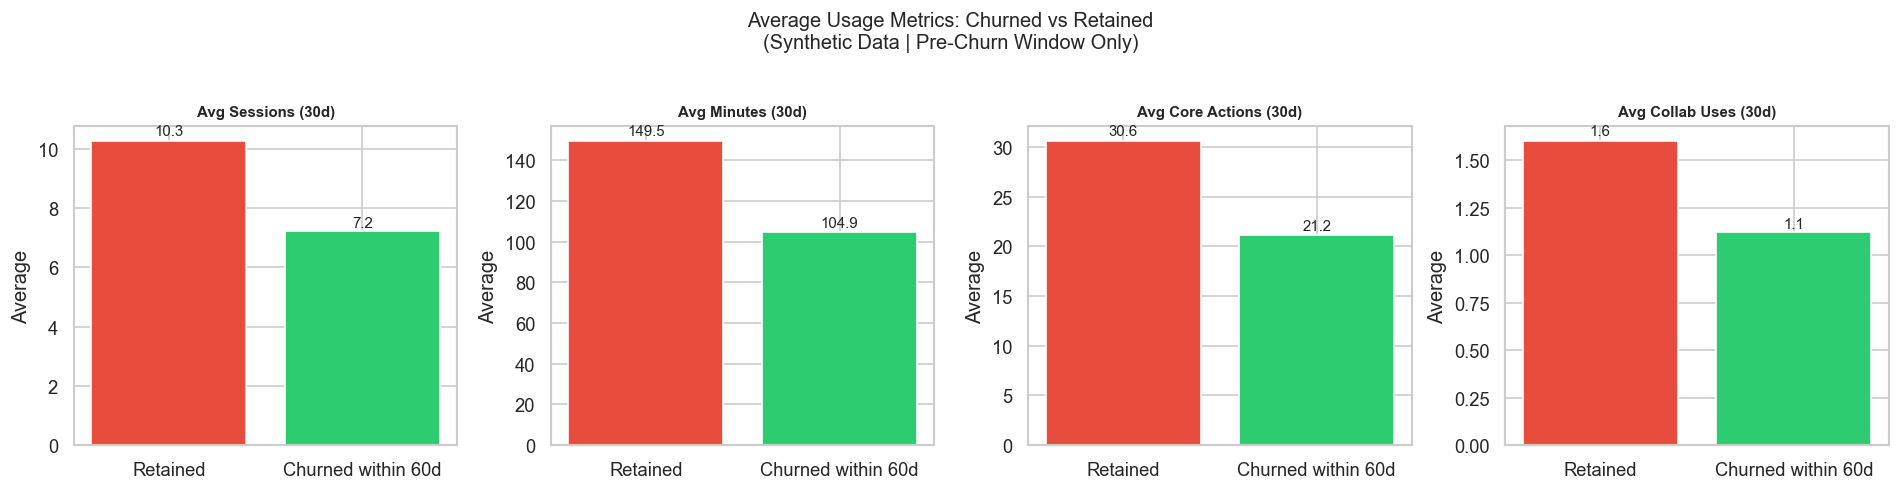

In [6]:
df_avg = pd.read_sql('SELECT * FROM avg_usage_by_churn_outcome', conn)
print(df_avg.to_string(index=False))

metrics = ['avg_sessions_30d', 'avg_minutes_30d', 'avg_core_actions_30d', 'avg_collab_uses_30d']
labels  = ['Avg Sessions (30d)', 'Avg Minutes (30d)', 'Avg Core Actions (30d)', 'Avg Collab Uses (30d)']

fig, axes = plt.subplots(1, len(metrics), figsize=(16, 4))
for ax, m, lab in zip(axes, metrics, labels):
    vals = df_avg.set_index('outcome')[m]
    colors = ['#e74c3c', '#2ecc71'] if vals.index[0] == 'Churned' else ['#2ecc71', '#e74c3c']
    ax.bar(vals.index, vals.values, color=['#e74c3c', '#2ecc71'], edgecolor='white')
    ax.set_title(lab, fontsize=9, fontweight='bold')
    ax.set_ylabel('Average')
    for i, (idx, val) in enumerate(vals.items()):
        ax.text(i, val + val*0.02, f'{val:.1f}', ha='center', fontsize=9)

plt.suptitle('Average Usage Metrics: Churned vs Retained\n(Synthetic Data | Pre-Churn Window Only)', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '05_avg_usage_churned_vs_retained.png', bbox_inches='tight')
plt.show()

## 4. Support Ticket Friction (Q10 preview)

In [7]:
df_tkt = pd.read_sql('SELECT * FROM churn_by_support_tickets ORDER BY churn_pct DESC', conn)
print(df_tkt.to_string(index=False))
print()
print('NOTE: Open tickets are a potential leading indicator.')
print('Full leading indicator analysis is in Notebook 06.')

   ticket_group  total_customers  churned  churn_pct
No open tickets             2221      312      14.05
  1 open ticket               28        0       0.00

NOTE: Open tickets are a potential leading indicator.
Full leading indicator analysis is in Notebook 06.


In [8]:
conn.close()